# Ejercicios a realizar

En el siguiente código Julia cambie `1234` por su código de estudiante y corra la celda. Con el resultado, realice los ejercicios del capítulo 4 de Serie Schaum en este mismo archivo. Escriba los enunciados y *todos* los procedimientos para resolver cada ejercicio. Si es necesario haga las gráficas adecuadas y use los paquetes de Julia que necesite para esto. Guarde este archivo ipynb en su cuenta de github y envíe la dirección al enlace Moodle de esta tarea.

![Schaum](prob.png)

In [27]:
using Random, Distributions
Random.seed!(2447968)

TaskLocalRNG()

In [28]:
sort!(sample([61:94; 98:104; 108:120],15,replace=false,ordered=false))

15-element Vector{Int64}:
  63
  67
  71
  84
  85
  90
  91
 102
 104
 108
 113
 114
 116
 117
 119

## Juan Sebastián Rodríguez Nonsoque

In [30]:
using Distributions
using Plots
using StatsPlots
using Statistics
using QuadGK
using Random

## Ejercicio 4.63

**Enunciado.** Si $X$ denota el número de caras al lanzar 4 monedas justas, hallar (a) $P(X=3)$, (b) $P(X<2)$, (c) $P(X\le 2)$, (d) $P(1<X\le 3)$.

**Procedimiento.** $X$ cuenta éxitos (caras) en $n=4$ ensayos independientes con $p=\tfrac12$, así que $X\sim \text{Bin}(4,\tfrac12)$:

$$f(x)=\binom{4}{x}\left(\tfrac12\right)^x\left(\tfrac12\right)^{4-x}=\frac{\binom{4}{x}}{16},\quad x=0,1,\dots,4$$

- (a) $P(X=3)=f(3)=\dfrac{4}{16}=0.25$
- (b) $P(X<2)=f(0)+f(1)=\dfrac{1+4}{16}=0.3125$
- (c) $P(X\le 2)=f(0)+f(1)+f(2)=\dfrac{1+4+6}{16}=0.6875$
- (d) $P(1<X\le 3)=f(2)+f(3)=\dfrac{6+4}{16}=0.625$

(a) P(X=3)     = 0.25
(b) P(X<2)     = 0.3125
(c) P(X≤2)     = 0.6875
(d) P(1<X≤3)   = 0.625


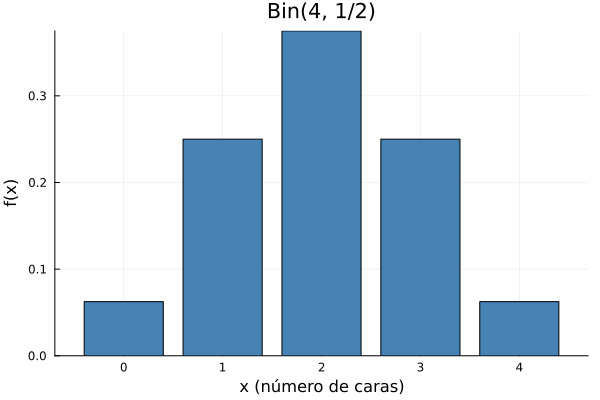

In [31]:
X = Binomial(4, 0.5)

pa = pdf(X, 3)                  # P(X = 3)
pb = pdf(X, 0) + pdf(X, 1)      # P(X < 2)
pc = cdf(X, 2)                  # P(X ≤ 2)
pd = pdf(X, 2) + pdf(X, 3)      # P(1 < X ≤ 3)

println("(a) P(X=3)     = ", pa)   # 0.25
println("(b) P(X<2)     = ", pb)   # 0.3125
println("(c) P(X≤2)     = ", pc)   # 0.6875
println("(d) P(1<X≤3)   = ", pd)   # 0.625

bar(0:4, pdf.(X, 0:4), label=false, xlabel="x (número de caras)",
    ylabel="f(x)", title="Bin(4, 1/2)", color=:steelblue, xticks=0:4)

## Ejercicio 4.67

**Enunciado.** Hallar la probabilidad de adivinar correctamente al menos 6 de las 10 respuestas en un examen de falso-verdadero.

**Procedimiento.** Al adivinar, cada respuesta es correcta con $p=\tfrac12$, así que $X\sim\text{Bin}(10,\tfrac12)$:

$$P(X\ge 6)=\sum_{x=6}^{10}\binom{10}{x}\left(\tfrac12\right)^{10}=\frac{210+120+45+10+1}{1024}=\frac{386}{1024}\approx 0.3770$$

P(X ≥ 6) = 0.3769531250000007  (verificación: 0.3769531250000003)


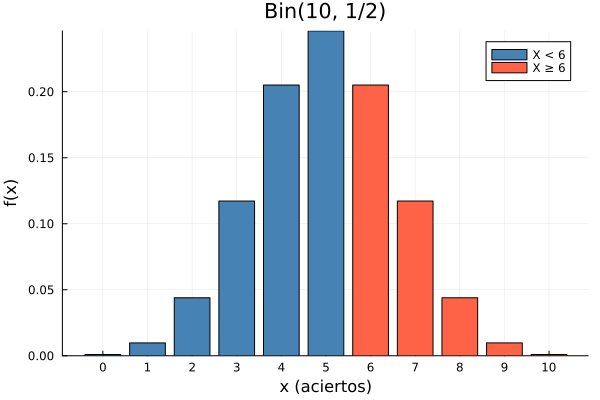

In [32]:
X = Binomial(10, 0.5)

p_suma  = sum(pdf(X, k) for k in 6:10)   # suma directa
p_ccdf  = ccdf(X, 5)                     # P(X > 5) = P(X ≥ 6)
println("P(X ≥ 6) = ", p_suma, "  (verificación: ", p_ccdf, ")")   # ≈ 0.3770

bar(0:5, pdf.(X, 0:5), label="X < 6", color=:steelblue)
bar!(6:10, pdf.(X, 6:10), label="X ≥ 6", color=:tomato,
     xlabel="x (aciertos)", ylabel="f(x)", title="Bin(10, 1/2)", xticks=0:10)

## Ejercicio 4.71

**Enunciado.** Evaluar (a) $\sum (x-\mu)^3 f(x)$, (b) $\sum (x-\mu)^4 f(x)$ para la distribución binomial.

**Procedimiento.** Sea $X\sim\text{Bin}(n,p)$, $q=1-p$, $\mu=np$. Escribimos $X=X_1+\dots+X_n$ con $X_i\sim\text{Bernoulli}(p)$ independientes y $Y_i=X_i-p$, de modo que $X-\mu=\sum Y_i$ y $E[Y_i]=0$.

Momentos de un solo ensayo ($Y_i$ vale $q$ con prob. $p$, y $-p$ con prob. $q$):

$$E[Y_i^2]=pq,\qquad E[Y_i^3]=pq^3-qp^3=pq(q-p),\qquad E[Y_i^4]=pq^4+qp^4=pq(1-3pq)$$

**(a)** Como las $Y_i$ son independientes con media cero, los términos cruzados se anulan:

$$\sum (x-\mu)^3 f(x)=E\Big[\big(\textstyle\sum Y_i\big)^3\Big]=n\,E[Y_i^3]=npq(q-p)$$

**(b)** En la cuarta potencia sobreviven los términos $Y_i^4$ y los pares $Y_i^2Y_j^2$ (hay $3n(n-1)$ de estos):

$$\sum (x-\mu)^4 f(x)=nE[Y_i^4]+3n(n-1)(pq)^2=npq\left[1-3pq+3(n-1)pq\right]=npq\left[1+3(n-2)pq\right]$$

A continuación se verifican ambas fórmulas numéricamente.

In [33]:
momento_central(n, p, r) = sum((x - n*p)^r * pdf(Binomial(n, p), x) for x in 0:n)

for (n, p) in [(10, 0.3), (20, 0.5), (50, 0.1)]
    q = 1 - p
    m3_num = momento_central(n, p, 3)
    m4_num = momento_central(n, p, 4)
    m3_formula = n*p*q*(q - p)
    m4_formula = n*p*q*(1 + 3*(n - 2)*p*q)
    println("n=$n, p=$p")
    println("  (a) suma = ", round(m3_num, digits=6), " | fórmula = ", round(m3_formula, digits=6))
    println("  (b) suma = ", round(m4_num, digits=6), " | fórmula = ", round(m4_formula, digits=6))
end

n=10, p=0.3
  (a) suma = 0.84 | fórmula = 0.84
  (b) suma = 12.684 | fórmula = 12.684
n=20, p=0.5
  (a) suma = 0.0 | fórmula = 0.0
  (b) suma = 72.5 | fórmula = 72.5
n=50, p=0.1
  (a) suma = 3.6 | fórmula = 3.6
  (b) suma = 62.82 | fórmula = 62.82


## Ejercicio 4.84

**Enunciado.** Si $\mu$ es la media y $\sigma$ la desviación estándar de un conjunto de mediciones normalmente distribuidas, ¿qué porcentaje de las mediciones están (a) dentro del rango $\mu\pm 2\sigma$, (b) fuera del rango $\mu\pm 1.2\sigma$, (c) por encima de $\mu-1.5\sigma$?

**Procedimiento.** Estandarizamos con $Z=\dfrac{X-\mu}{\sigma}\sim N(0,1)$ y usamos la función de distribución $\Phi$:

- (a) $P(\mu-2\sigma<X<\mu+2\sigma)=P(-2<Z<2)=\Phi(2)-\Phi(-2)$
- (b) $P(|Z|>1.2)=1-[\Phi(1.2)-\Phi(-1.2)]=2\,[1-\Phi(1.2)]$
- (c) $P(X>\mu-1.5\sigma)=P(Z>-1.5)=1-\Phi(-1.5)$


(a) 95.45 %
(b) 23.01 %
(c) 93.32 %


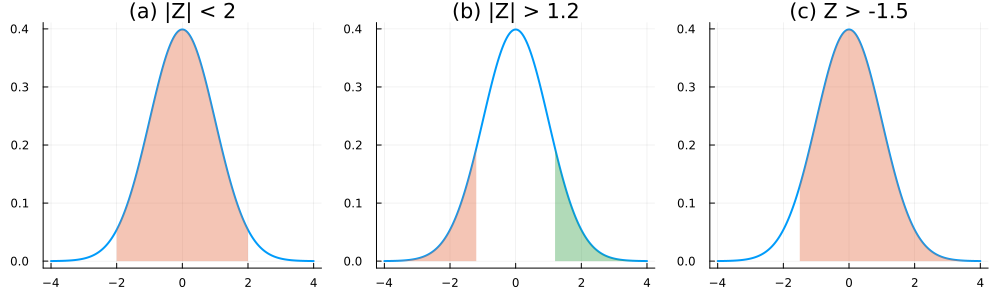

In [34]:
Z = Normal(0, 1)

pa = cdf(Z, 2) - cdf(Z, -2)             # ≈ 0.9545
pb = 1 - (cdf(Z, 1.2) - cdf(Z, -1.2))   # ≈ 0.2301
pc = ccdf(Z, -1.5)                      # ≈ 0.9332

println("(a) ", round(100*pa, digits=2), " %")
println("(b) ", round(100*pb, digits=2), " %")
println("(c) ", round(100*pc, digits=2), " %")

# Gráficas
x = -4:0.01:4
base(t) = plot(x, pdf.(Z, x), lw=2, label=false, title=t, xlabel="z")
sombra!(p, lo, hi) = plot!(p, range(lo, hi, length=200), pdf.(Z, range(lo, hi, length=200)),
                           fill=(0, 0.4), lw=0, label=false)

p1 = base("(a) |Z| < 2");   sombra!(p1, -2, 2)
p2 = base("(b) |Z| > 1.2"); sombra!(p2, -4, -1.2); sombra!(p2, 1.2, 4)
p3 = base("(c) Z > -1.5");  sombra!(p3, -1.5, 4)
plot(p1, p2, p3, layout=(1, 3), size=(1000, 300))

## Ejercicio 4.85

**Enunciado.** En el problema 4.84 hallar la constante $a$ tal que el porcentaje de casos (a) dentro del rango $\mu\pm a\sigma$ sea 75%, (b) menor que $\mu-a\sigma$ sea 22%.

**Procedimiento.**

- (a) Se requiere $P(-a<Z<a)=0.75$. Por simetría, $\Phi(a)-\Phi(-a)=2\Phi(a)-1=0.75$, así que $\Phi(a)=0.875$ y
  $$a=\Phi^{-1}(0.875)$$
- (b) Se requiere $P(Z<-a)=\Phi(-a)=0.22$, así que $-a=\Phi^{-1}(0.22)$ y
  $$a=-\Phi^{-1}(0.22)$$


(a) a = 1.1503
(b) a = 0.7722
Verif. (a): 0.75
Verif. (b): 0.2199999999999999


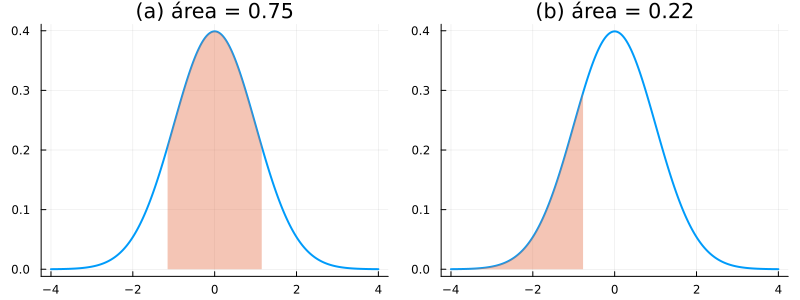

In [35]:
Z = Normal(0, 1)

a_a = quantile(Z, 0.875)     # ≈ 1.15
a_b = -quantile(Z, 0.22)     # ≈ 0.77

println("(a) a = ", round(a_a, digits=4))
println("(b) a = ", round(a_b, digits=4))

# Verificación
println("Verif. (a): ", cdf(Z, a_a) - cdf(Z, -a_a))   # 0.75
println("Verif. (b): ", cdf(Z, -a_b))                  # 0.22

x = -4:0.01:4
sombra!(p, lo, hi) = plot!(p, range(lo, hi, length=200), pdf.(Z, range(lo, hi, length=200)),
                           fill=(0, 0.4), lw=0, label=false)
p1 = plot(x, pdf.(Z, x), lw=2, label=false, title="(a) área = 0.75");  sombra!(p1, -a_a, a_a)
p2 = plot(x, pdf.(Z, x), lw=2, label=false, title="(b) área = 0.22");  sombra!(p2, -4, -a_b)
plot(p1, p2, layout=(1, 2), size=(800, 300))

## Ejercicio 4.90

**Enunciado.** Si el 3% de los bombillos eléctricos fabricados por una empresa son defectuosos, hallar la probabilidad de que en una muestra de 100 bombillos (a) 0, (b) 1, (c) 2, (d) 3, (e) 4, (f) 5 sean defectuosos.

**Procedimiento.** Sea $X$ el número de bombillos defectuosos; $X\sim\text{Bin}(100,\,0.03)$:

$$P(X=k)=\binom{100}{k}(0.03)^k(0.97)^{100-k}$$

Como $n$ es grande y $p$ pequeño, se aproxima con Poisson de parámetro $\lambda=np=3$:

$$P(X=k)\approx \frac{e^{-3}\,3^k}{k!}$$

Se calculan ambas y se comparan.

k | Binomial exacta | Poisson (λ=3)
0 | 0.0476 | 0.0498
1 | 0.1471 | 0.1494
2 | 0.2252 | 0.224
3 | 0.2275 | 0.224
4 | 0.1706 | 0.168
5 | 0.1013 | 0.1008


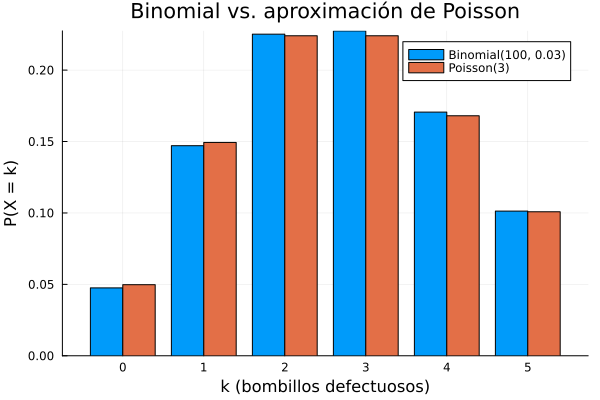

In [36]:
n, p = 100, 0.03
B = Binomial(n, p)
P = Poisson(n * p)      # λ = 3

ks = 0:5
println("k | Binomial exacta | Poisson (λ=3)")
for k in ks
    println(k, " | ", round(pdf(B, k), digits=4), " | ", round(pdf(P, k), digits=4))
end
# Poisson: 0.0498, 0.1494, 0.2240, 0.2240, 0.1680, 0.1008

groupedbar(collect(ks), [pdf.(B, ks) pdf.(P, ks)],
           label=["Binomial(100, 0.03)" "Poisson(3)"],
           xlabel="k (bombillos defectuosos)", ylabel="P(X = k)",
           title="Binomial vs. aproximación de Poisson", xticks=0:5)

## Ejercicio 4.91

**Enunciado.** En el problema 4.90 hallar la probabilidad de que (a) más de 5, (b) entre 1 y 3, (c) menos o igual a 2 bombillos sean defectuosos.

**Procedimiento.** Con la aproximación de Poisson ($\lambda=3$); "entre 1 y 3" se toma de forma inclusiva:

- (a) $P(X>5)=1-P(X\le 5)=1-\sum_{k=0}^{5}\dfrac{e^{-3}3^k}{k!}$
- (b) $P(1\le X\le 3)=P(1)+P(2)+P(3)$
- (c) $P(X\le 2)=P(0)+P(1)+P(2)$

                     Poisson   Binomial
(a) P(X > 5)       = 0.0839   0.0808
(b) P(1 ≤ X ≤ 3)   = 0.5974   0.5997
(c) P(X ≤ 2)       = 0.4232   0.4198


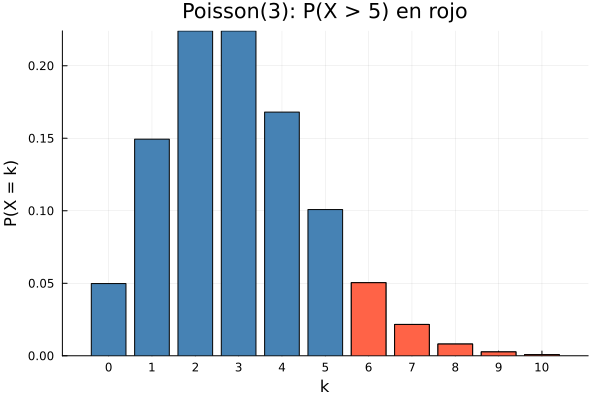

In [37]:
n, p = 100, 0.03
P = Poisson(n * p)
B = Binomial(n, p)

pa_P = ccdf(P, 5)                         # ≈ 0.0839
pb_P = sum(pdf(P, k) for k in 1:3)        # ≈ 0.5974
pc_P = cdf(P, 2)                          # ≈ 0.4232

pa_B = ccdf(B, 5)
pb_B = sum(pdf(B, k) for k in 1:3)
pc_B = cdf(B, 2)

println("                     Poisson   Binomial")
println("(a) P(X > 5)       = ", round(pa_P, digits=4), "   ", round(pa_B, digits=4))
println("(b) P(1 ≤ X ≤ 3)   = ", round(pb_P, digits=4), "   ", round(pb_B, digits=4))
println("(c) P(X ≤ 2)       = ", round(pc_P, digits=4), "   ", round(pc_B, digits=4))

ks = 0:10
bar(ks, pdf.(P, ks), label=false, color=:steelblue, xlabel="k", ylabel="P(X = k)",
    title="Poisson(3): P(X > 5) en rojo", xticks=0:10)
bar!(6:10, pdf.(P, 6:10), label=false, color=:tomato)

## Ejercicio 4.102

**Enunciado.** Hallar (a) el tercer, (b) el cuarto momento respecto a la media de una distribución uniforme.

**Procedimiento.** Sea $X\sim U(a,b)$ con $f(x)=\dfrac{1}{b-a}$ en $[a,b]$. La media es $\mu=\dfrac{a+b}{2}$. Con $h=\dfrac{b-a}{2}$, la variable $Y=X-\mu$ es uniforme en $[-h,h]$:

$$\mu_r=E[(X-\mu)^r]=\frac{1}{2h}\int_{-h}^{h}y^r\,dy=\frac{1}{2h}\cdot\frac{h^{r+1}-(-h)^{r+1}}{r+1}$$

- (a) $r=3$: la integral de una función impar sobre un intervalo simétrico es cero, así que $\mu_3=0$.
- (b) $r=4$: $\mu_4=\dfrac{1}{2h}\cdot\dfrac{2h^5}{5}=\dfrac{h^4}{5}=\dfrac{(b-a)^4}{80}$.

Se verifica numéricamente con $a=2$, $b=7$.

(a) μ₃ numérico = 0.0   teórico = 0
(b) μ₄ numérico = 7.8125   teórico = (b-a)^4/80 = 7.8125


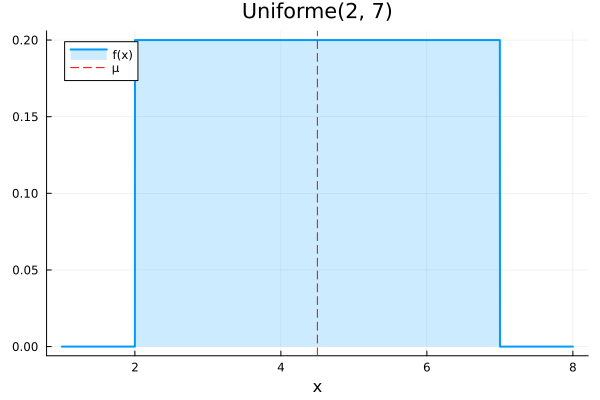

In [38]:
a, b = 2.0, 7.0
U = Uniform(a, b)
μ = mean(U)

μ3, _ = quadgk(x -> (x - μ)^3 * pdf(U, x), a, b)
μ4, _ = quadgk(x -> (x - μ)^4 * pdf(U, x), a, b)

println("(a) μ₃ numérico = ", round(μ3, digits=8), "   teórico = 0")
println("(b) μ₄ numérico = ", round(μ4, digits=6), "   teórico = (b-a)^4/80 = ", (b - a)^4 / 80)

plot(x -> pdf(U, x), a - 1, b + 1, lw=2, label="f(x)", xlabel="x",
     title="Uniforme(2, 7)", fill=(0, 0.2))
vline!([μ], ls=:dash, color=:red, label="μ")

## Ejercicio 4.104

**Enunciado.** Si $X$ y $Y$ son independientes y ambas uniformemente distribuidas en el intervalo de 0 a 1, hallar $P\left(|X-Y|\ge \tfrac12\right)$.

**Procedimiento.** El par $(X,Y)$ es uniforme en el cuadrado unitario, así que la probabilidad es el área de la región favorable. La condición $|X-Y|\ge\tfrac12$ equivale a $y\ge x+\tfrac12$ o $y\le x-\tfrac12$: dos triángulos rectángulos de catetos $\tfrac12$, cada uno de área $\tfrac12\cdot\tfrac12\cdot\tfrac12=\tfrac18$.

$$P\left(|X-Y|\ge\tfrac12\right)=\tfrac18+\tfrac18=\tfrac14$$

Equivalente por integración: $\displaystyle\int_0^1\left[\max(0,x-\tfrac12)+\max(0,\tfrac12-x)\right]dx=\tfrac14$.

Por integración: 0.25
Monte Carlo:     0.250091


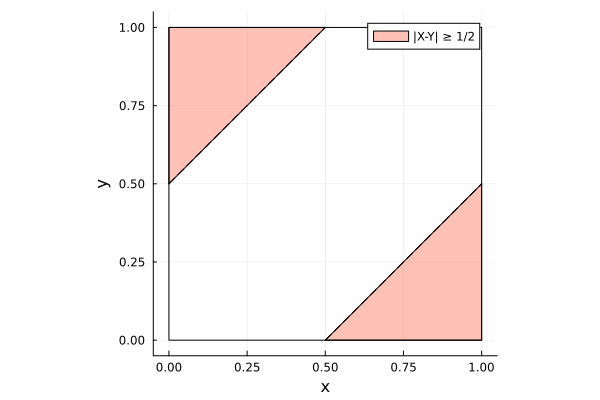

In [39]:
# Integral exacta (con el punto de quiebre en x = 1/2)
f(x) = max(0, x - 0.5) + max(0, 0.5 - x)
p_int, _ = quadgk(f, 0, 0.5, 1)
println("Por integración: ", p_int)          # 0.25

# Simulación Monte Carlo
Random.seed!(123)
N = 10^6
x = rand(N); y = rand(N)
println("Monte Carlo:     ", mean(abs.(x .- y) .>= 0.5))   # ≈ 0.25

# Gráfica de la región
plot(Shape([0, 0, 0.5], [0.5, 1, 1]), fillalpha=0.4, color=:tomato, label="|X-Y| ≥ 1/2")
plot!(Shape([0.5, 1, 1], [0, 0, 0.5]), fillalpha=0.4, color=:tomato, label=false)
plot!([0, 1, 1, 0, 0], [0, 0, 1, 1, 0], color=:black, label=false)
plot!([0, 0.5], [0.5, 1], color=:black, ls=:dash, label=false)
plot!([0.5, 1], [0, 0.5], color=:black, ls=:dash, label=false)
plot!(xlabel="x", ylabel="y", aspect_ratio=1, xlims=(-0.05, 1.05), ylims=(-0.05, 1.05))

## Ejercicio 4.108

**Enunciado.** Una variable aleatoria $X$ tiene distribución gamma con $\alpha=3$, $\beta=2$. Hallar (a) $P(X\le 1)$, (b) $P(1\le X\le 2)$.

**Procedimiento.** Con $\beta$ como parámetro de escala, la densidad es

$$f(x)=\frac{x^{\alpha-1}e^{-x/\beta}}{\beta^\alpha\,\Gamma(\alpha)}=\frac{x^2e^{-x/2}}{16},\quad x>0$$

Para $\alpha$ entero la distribución acumulada tiene forma cerrada:

$$F(x)=1-e^{-x/\beta}\sum_{k=0}^{\alpha-1}\frac{(x/\beta)^k}{k!}=1-e^{-x/2}\left[1+\frac{x}{2}+\frac{x^2}{8}\right]$$

- (a) $P(X\le1)=F(1)=1-e^{-1/2}(1.625)\approx 0.0144$
- (b) $P(1\le X\le 2)=F(2)-F(1)=\left[1-2.5\,e^{-1}\right]-0.0144\approx 0.0659$

(a) P(X ≤ 1)     = 0.0144  (forma cerrada: 0.0144)
(b) P(1 ≤ X ≤ 2) = 0.0659  (forma cerrada: 0.0659)


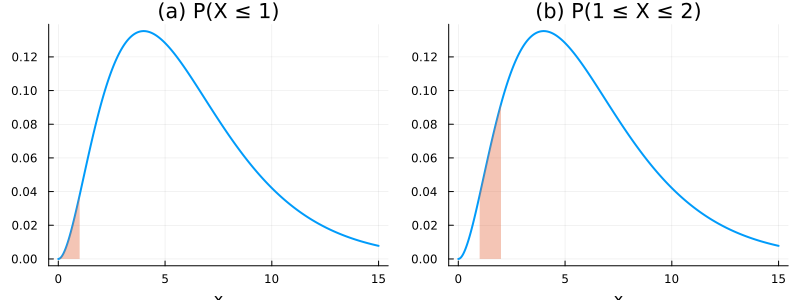

In [40]:
X = Gamma(3, 2)      # Gamma(forma α, escala β)

# Forma cerrada
F(x) = 1 - exp(-x/2) * (1 + x/2 + x^2/8)

pa = cdf(X, 1)                 # ≈ 0.0144
pb = cdf(X, 2) - cdf(X, 1)     # ≈ 0.0659

println("(a) P(X ≤ 1)     = ", round(pa, digits=4), "  (forma cerrada: ", round(F(1), digits=4), ")")
println("(b) P(1 ≤ X ≤ 2) = ", round(pb, digits=4), "  (forma cerrada: ", round(F(2) - F(1), digits=4), ")")

x = 0:0.01:15
p1 = plot(x, pdf.(X, x), lw=2, label=false, title="(a) P(X ≤ 1)", xlabel="x")
xs = range(0, 1, length=100);  plot!(p1, xs, pdf.(X, xs), fill=(0, 0.4), lw=0, label=false)
p2 = plot(x, pdf.(X, x), lw=2, label=false, title="(b) P(1 ≤ X ≤ 2)", xlabel="x")
xs = range(1, 2, length=100);  plot!(p2, xs, pdf.(X, xs), fill=(0, 0.4), lw=0, label=false)
plot(p1, p2, layout=(1, 2), size=(800, 300))

## Ejercicio 4.113

**Enunciado.** Si la variable $U$ tiene distribución chi-cuadrado con $\nu=7$, hallar $\chi_1^2$ y $\chi_2^2$ tales que (a) $P(U>\chi_2^2)=0.025$, (b) $P(U<\chi_1^2)=0.50$, (c) $P(\chi_1^2\le U\le\chi_2^2)=0.90$.

**Procedimiento.** Usamos la función cuantil (inversa de la acumulada) $F^{-1}$ de $\chi^2_7$:

- (a) $P(U>\chi_2^2)=0.025\Rightarrow F(\chi_2^2)=0.975\Rightarrow \chi_2^2=F^{-1}(0.975)$
- (b) $F(\chi_1^2)=0.50\Rightarrow \chi_1^2=F^{-1}(0.50)$ (la mediana)
- (c) Se toman colas iguales de 0.05: $\chi_1^2=F^{-1}(0.05)$ y $\chi_2^2=F^{-1}(0.95)$, de modo que el área central sea 0.90.

(a) χ₂² = 16.013
(b) χ₁² = 6.346
(c) χ₁² = 2.167,  χ₂² = 14.067
Verif. (c): 0.8999999999999999


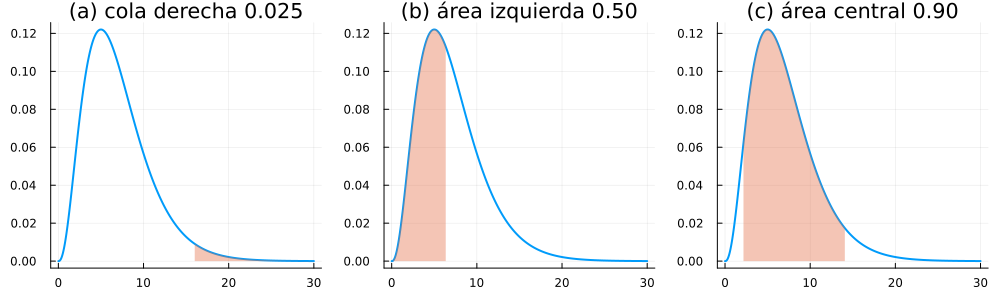

In [41]:
U = Chisq(7)

chi2_a  = quantile(U, 0.975)    # ≈ 16.01
chi1_b  = quantile(U, 0.50)     # ≈ 6.346
chi1_c  = quantile(U, 0.05)     # ≈ 2.167
chi2_c  = quantile(U, 0.95)     # ≈ 14.07

println("(a) χ₂² = ", round(chi2_a, digits=3))
println("(b) χ₁² = ", round(chi1_b, digits=3))
println("(c) χ₁² = ", round(chi1_c, digits=3), ",  χ₂² = ", round(chi2_c, digits=3))
println("Verif. (c): ", cdf(U, chi2_c) - cdf(U, chi1_c))   # 0.90

x = 0:0.01:30
p1 = plot(x, pdf.(U, x), lw=2, label=false, title="(a) cola derecha 0.025", xlabel="u")
xs = range(chi2_a, 30, length=100); plot!(p1, xs, pdf.(U, xs), fill=(0, 0.4), lw=0, label=false)
p2 = plot(x, pdf.(U, x), lw=2, label=false, title="(b) área izquierda 0.50", xlabel="u")
xs = range(0, chi1_b, length=100); plot!(p2, xs, pdf.(U, xs), fill=(0, 0.4), lw=0, label=false)
p3 = plot(x, pdf.(U, x), lw=2, label=false, title="(c) área central 0.90", xlabel="u")
xs = range(chi1_c, chi2_c, length=100); plot!(p3, xs, pdf.(U, xs), fill=(0, 0.4), lw=0, label=false)
plot(p1, p2, p3, layout=(1, 3), size=(1000, 300))

## Ejercicio 4.114

**Enunciado.** Hallar (a) $\chi^2_{0.05}$ y (b) $\chi^2_{0.95}$ para $\nu=150$.

**Procedimiento.** Aquí $\chi^2_p$ es el percentil $p$, es decir, el valor con área $p$ a su izquierda: $\chi^2_p=F^{-1}(p)$. Como $\nu=150$ excede lo que traen las tablas usuales, se usa la aproximación normal

$$\chi^2_p\approx\frac{1}{2}\left(z_p+\sqrt{2\nu-1}\right)^2,\qquad \sqrt{2\nu-1}=\sqrt{299}\approx17.29$$

donde $z_p$ es el percentil $p$ de la normal estándar. Se compara con el valor exacto.

(a) χ²₀.₀₅: exacto = 122.69  aproximación = 122.41
(b) χ²₀.₉₅: exacto = 179.58  aproximación = 179.29


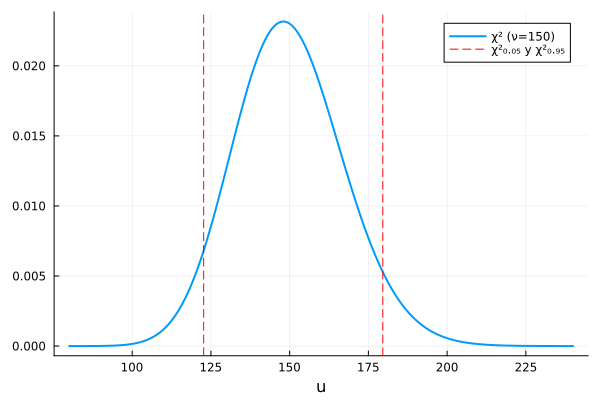

In [42]:
ν = 150
U = Chisq(ν)
Z = Normal(0, 1)

aprox(p) = 0.5 * (quantile(Z, p) + sqrt(2ν - 1))^2

println("(a) χ²₀.₀₅: exacto = ", round(quantile(U, 0.05), digits=2),
        "  aproximación = ", round(aprox(0.05), digits=2))   # ≈ 122.69 vs 122.4
println("(b) χ²₀.₉₅: exacto = ", round(quantile(U, 0.95), digits=2),
        "  aproximación = ", round(aprox(0.95), digits=2))   # ≈ 179.58 vs 179.3

x = 80:0.1:240
plot(x, pdf.(U, x), lw=2, label="χ² (ν=150)", xlabel="u")
vline!([quantile(U, 0.05), quantile(U, 0.95)], ls=:dash, color=:red, label="χ²₀.₀₅ y χ²₀.₉₅")

## Ejercicio 4.116

**Enunciado.** Para una distribución t de Student con 15 grados de libertad, hallar el valor de $t_1$ tal que (a) el área a la derecha de $t_1$ sea 0.01, (b) el área a la izquierda de $t_1$ sea 0.95, (c) el área a la derecha de $t_1$ sea 0.10, (d) el área combinada a la derecha de $t_1$ y a la izquierda de $-t_1$ sea 0.01, (e) el área entre $-t_1$ y $t_1$ sea 0.95.

**Procedimiento.** Con $T\sim t_{15}$ y su cuantil $F^{-1}$, usando la simetría de la distribución:

- (a) $1-F(t_1)=0.01\Rightarrow t_1=F^{-1}(0.99)$
- (b) $F(t_1)=0.95\Rightarrow t_1=F^{-1}(0.95)$
- (c) $1-F(t_1)=0.10\Rightarrow t_1=F^{-1}(0.90)$
- (d) Dos colas iguales suman 0.01, o sea 0.005 cada una: $t_1=F^{-1}(0.995)$
- (e) El área central es 0.95, quedan 0.025 por cola: $t_1=F^{-1}(0.975)$

(a) t₁ = 2.602
(b) t₁ = 1.753
(c) t₁ = 1.341
(d) t₁ = 2.947
(e) t₁ = 2.131


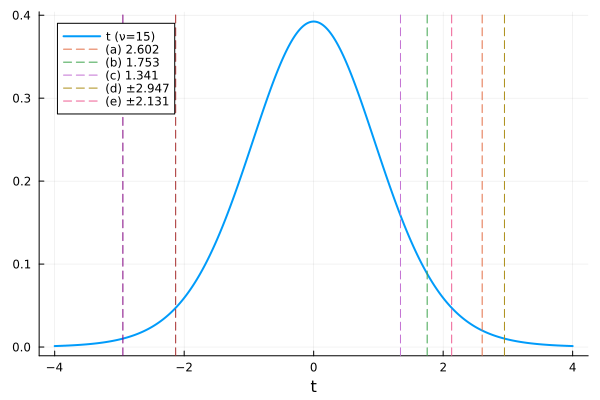

In [43]:
T = TDist(15)

t_a = quantile(T, 0.99)     # ≈ 2.602
t_b = quantile(T, 0.95)     # ≈ 1.753
t_c = quantile(T, 0.90)     # ≈ 1.341
t_d = quantile(T, 0.995)    # ≈ 2.947
t_e = quantile(T, 0.975)    # ≈ 2.131

for (inciso, t) in zip("abcde", [t_a, t_b, t_c, t_d, t_e])
    println("($inciso) t₁ = ", round(t, digits=3))
end

x = -4:0.01:4
plot(x, pdf.(T, x), lw=2, label="t (ν=15)", xlabel="t")
vline!([t_a], label="(a) 2.602", ls=:dash)
vline!([t_b], label="(b) 1.753", ls=:dash)
vline!([t_c], label="(c) 1.341", ls=:dash)
vline!([t_d], label="(d) ±2.947", ls=:dash)
vline!([-t_d], label=false, ls=:dash, color=:purple)
vline!([t_e], label="(e) ±2.131", ls=:dash)
vline!([-t_e], label=false, ls=:dash, color=:brown)

## Ejercicio 4.117

**Enunciado.** Hallar los valores de $t$ para los cuales el área de la cola derecha de la distribución $t$ es 0.01, si el número de grados de libertad $\nu$ es igual a (a) 4, (b) 12, (c) 25, (d) 60, (e) 150.

**Procedimiento.** Para cada $\nu$ se busca $t_{0.99}$ tal que $P(T>t)=0.01$, es decir $F_\nu(t)=0.99$, de modo que $t=F_\nu^{-1}(0.99)$. A medida que $\nu$ crece, $t$ se acerca a $z_{0.99}\approx 2.326$ de la normal estándar.

ν   | t (cola derecha = 0.01)
(a) ν=4 | 3.747
(b) ν=12 | 2.681
(c) ν=25 | 2.485
(d) ν=60 | 2.39
(e) ν=150 | 2.351
Normal estándar: z₀.₉₉ = 2.326


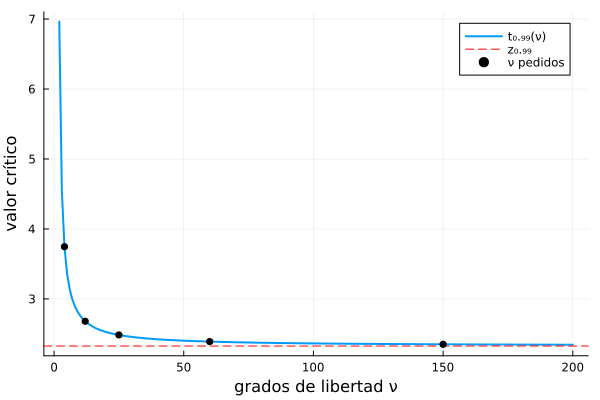

In [44]:
νs = [4, 12, 25, 60, 150]

println("ν   | t (cola derecha = 0.01)")
for (inciso, ν) in zip("abcde", νs)
    println("($inciso) ν=$ν | ", round(quantile(TDist(ν), 0.99), digits=3))
end
println("Normal estándar: z₀.₉₉ = ", round(quantile(Normal(), 0.99), digits=3))

# Cómo converge t₀.₉₉ a z₀.₉₉ al crecer ν
ν_rango = 2:200
plot(ν_rango, [quantile(TDist(ν), 0.99) for ν in ν_rango], lw=2, label="t₀.₉₉(ν)",
     xlabel="grados de libertad ν", ylabel="valor crítico")
hline!([quantile(Normal(), 0.99)], ls=:dash, color=:red, label="z₀.₉₉")
scatter!(νs, [quantile(TDist(ν), 0.99) for ν in νs], label="ν pedidos", color=:black)

## Ejercicio 4.119

**Enunciado.** Si una variable $U$ tiene distribución t de Student con $\nu=10$, hallar la constante $c$ tal que (a) $P(U>c)=0.05$, (b) $P(-c\le U\le c)=0.98$, (c) $P(U\le c)=0.20$, (d) $P(U\ge c)=0.90$.

**Procedimiento.** Con $U\sim t_{10}$ y su cuantil $F^{-1}$:

- (a) $P(U>c)=0.05\Rightarrow F(c)=0.95\Rightarrow c=F^{-1}(0.95)$
- (b) El área central es 0.98, quedan 0.01 por cola: $c=F^{-1}(0.99)$
- (c) $F(c)=0.20\Rightarrow c=F^{-1}(0.20)$ (negativo, pues 0.20 < 0.5)
- (d) $P(U\ge c)=0.90\Rightarrow F(c)=0.10\Rightarrow c=F^{-1}(0.10)$ (negativo)

(a) c = 1.812
(b) c = 2.764
(c) c = -0.879
(d) c = -1.372
0.050000000000000024  0.98  0.20000000000000018  0.9


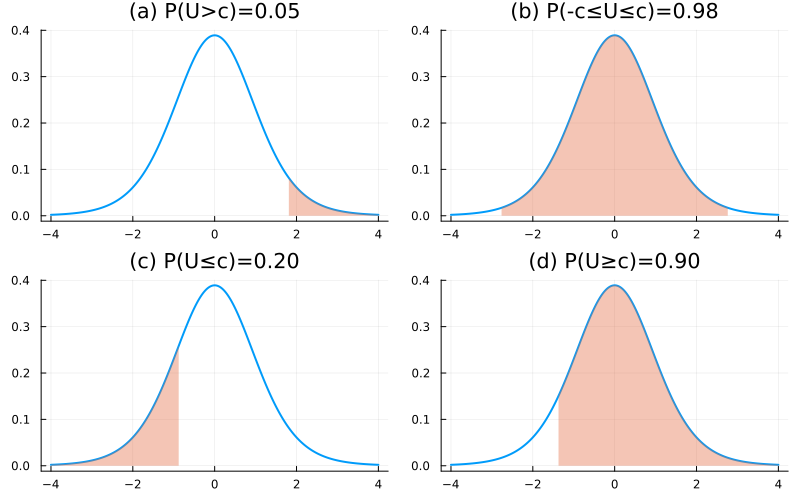

In [45]:
U = TDist(10)

c_a = quantile(U, 0.95)     # ≈ 1.812
c_b = quantile(U, 0.99)     # ≈ 2.764
c_c = quantile(U, 0.20)     # ≈ -0.879
c_d = quantile(U, 0.10)     # ≈ -1.372

println("(a) c = ", round(c_a, digits=3))
println("(b) c = ", round(c_b, digits=3))
println("(c) c = ", round(c_c, digits=3))
println("(d) c = ", round(c_d, digits=3))

# Verificaciones
println(ccdf(U, c_a), "  ", cdf(U, c_b) - cdf(U, -c_b), "  ", cdf(U, c_c), "  ", ccdf(U, c_d))

x = -4:0.01:4
sombra!(p, lo, hi) = plot!(p, range(lo, hi, length=200), pdf.(U, range(lo, hi, length=200)),
                           fill=(0, 0.4), lw=0, label=false)
p1 = plot(x, pdf.(U, x), lw=2, label=false, title="(a) P(U>c)=0.05");      sombra!(p1, c_a, 4)
p2 = plot(x, pdf.(U, x), lw=2, label=false, title="(b) P(-c≤U≤c)=0.98");   sombra!(p2, -c_b, c_b)
p3 = plot(x, pdf.(U, x), lw=2, label=false, title="(c) P(U≤c)=0.20");      sombra!(p3, -4, c_c)
p4 = plot(x, pdf.(U, x), lw=2, label=false, title="(d) P(U≥c)=0.90");      sombra!(p4, c_d, 4)
plot(p1, p2, p3, p4, layout=(2, 2), size=(800, 500))